# 01. Análisis exploratorio de datos (EDA) — ONPE 2026

## Objetivo
Explorar los JSON descargados desde la ONPE para conocer su cantidad, organización, estructura y calidad antes de generar y validar unidades textuales. 

Rutas: `data/raw/ONPE_2026/Peru/` y `notebooks/01_exploracion_datos.ipynb`.


## 1. Preparar el entorno
Usaremos Python, pandas y matplotlib. No necesitamos una base de datos para este análisis inicial.

In [10]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 50)

def encontrar_raiz(inicio: Path) -> Path:
    inicio = inicio.resolve()
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "data" / "raw").exists() or (candidato / "README.md").exists():
            return candidato
    return inicio.parent if inicio.name == "notebooks" else inicio

RAIZ = encontrar_raiz(Path.cwd())
RUTA_JSON = RAIZ / "data" / "raw" / "ONPE_2026" / "Peru"
print("Directorio actual:", Path.cwd().resolve())
print("Raíz del proyecto:", RAIZ)
print("Ruta de JSON:", RUTA_JSON)
print("Carpeta encontrada:", RUTA_JSON.exists())
if not RUTA_JSON.exists():
    print("Revisa la ruta o espera a que la descarga cree la carpeta.")


Directorio actual: C:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis\notebooks
Raíz del proyecto: C:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis
Ruta de JSON: C:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis\data\raw\ONPE_2026\Peru
Carpeta encontrada: True


## 2. Inventario de archivos
Contamos los JSON, sus tamaños y rutas relativas para conocer el dataset.

In [11]:
archivos_json = sorted(RUTA_JSON.rglob("*.json")) if RUTA_JSON.exists() else []
print(f"JSON encontrados: {len(archivos_json):,}")
inventario = []
for archivo in archivos_json:
    rel = archivo.relative_to(RUTA_JSON)
    tam = archivo.stat().st_size
    inventario.append({"archivo": archivo.name, "ruta_relativa": str(rel), "carpeta_padre": str(rel.parent), "tamano_bytes": tam, "tamano_kb": round(tam / 1024, 2)})
df_inventario = pd.DataFrame(inventario)
display(df_inventario.head(25))
if not df_inventario.empty:
    print("Tamaño total (MB):", round(df_inventario["tamano_bytes"].sum() / 1024**2, 2))
    display(df_inventario["archivo"].value_counts().rename_axis("nombre").reset_index(name="cantidad"))


JSON encontrados: 4,450


,archivo,ruta_relativa,carpeta_padre,tamano_bytes,tamano_kb
0,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS,9006,8.79
1,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS,477,0.47
2,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN,8903,8.69
3,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN,471,0.46
4,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS,8929,8.72
5,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS,471,0.46
6,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO,8905,8.70
7,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO,471,0.46
8,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN,8909,8.70
9,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN,471,0.46


Tamaño total (MB): 19.12


,nombre,cantidad
0,participantes.json,2113
1,totales.json,2113
2,distritos.json,196
3,provincias.json,25
4,departamentos.json,1
5,participantes_nacional.json,1
6,totales_nacional.json,1


## 3. Validar la lectura de los JSON
Un archivo puede tener extensión `.json` y estar vacío, truncado o tener un formato inesperado.

In [12]:
estados = []
for archivo in archivos_json:
    try:
        if archivo.stat().st_size == 0:
            estados.append({"archivo": str(archivo.relative_to(RUTA_JSON)), "estado": "vacío", "tipo_raiz": None, "detalle": "0 bytes"})
            continue
        with archivo.open("r", encoding="utf-8-sig") as f:
            obj = json.load(f)
        estados.append({"archivo": str(archivo.relative_to(RUTA_JSON)), "estado": "JSON válido", "tipo_raiz": type(obj).__name__, "detalle": ""})
    except Exception as e:
        estados.append({"archivo": str(archivo.relative_to(RUTA_JSON)), "estado": "error", "tipo_raiz": None, "detalle": str(e)[:200]})
df_estado = pd.DataFrame(estados)
if not df_estado.empty:
    display(df_estado["estado"].value_counts().rename_axis("estado").reset_index(name="cantidad"))
    display(df_estado[df_estado["estado"] != "JSON válido"].head(30))
else:
    print("No se encontraron archivos JSON.")


,estado,cantidad
0,JSON válido,4450


,archivo,estado,tipo_raiz,detalle


## 4. Inspeccionar la estructura
La API puede devolver campos `success`, `message` y `data`, pero no asumimos que todos los archivos tengan esa forma.

In [13]:
def leer_json(archivo):
    with archivo.open("r", encoding="utf-8-sig") as f:
        return json.load(f)

def estructura(obj, nivel=0, max_nivel=2):
    if isinstance(obj, dict):
        r = {"tipo": "dict", "cantidad_claves": len(obj), "claves": list(obj.keys())[:30]}
        if nivel < max_nivel:
            r["muestra_valores"] = {str(k): estructura(v, nivel + 1, max_nivel) for k, v in list(obj.items())[:8]}
        return r
    if isinstance(obj, list):
        r = {"tipo": "list", "cantidad_elementos": len(obj)}
        if obj: r["primer_elemento"] = estructura(obj[0], nivel + 1, max_nivel)
        return r
    return {"tipo": type(obj).__name__, "muestra": repr(obj)[:80]}

validos = []
for archivo in archivos_json:
    try: leer_json(archivo); validos.append(archivo)
    except Exception: pass
print("JSON legibles:", len(validos))
for archivo in validos[:5]:
    print("\nArchivo:", archivo.relative_to(RUTA_JSON))
    display(estructura(leer_json(archivo)))


JSON legibles: 4450

Archivo: 010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json


{'tipo': 'dict',
 'cantidad_claves': 3,
 'claves': ['success', 'message', 'data'],
 'muestra_valores': {'success': {'tipo': 'bool', 'muestra': 'True'},
  'message': {'tipo': 'str', 'muestra': "''"},
  'data': {'tipo': 'list',
   'cantidad_elementos': 36,
   'primer_elemento': {'tipo': 'dict',
    'cantidad_claves': 7,
    'claves': ['nombreAgrupacionPolitica',
     'codigoAgrupacionPolitica',
     'nombreCandidato',
     'dniCandidato',
     'totalVotosValidos',
     'porcentajeVotosValidos',
     'porcentajeVotosEmitidos']}}}}


Archivo: 010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json


{'tipo': 'dict',
 'cantidad_claves': 3,
 'claves': ['success', 'message', 'data'],
 'muestra_valores': {'success': {'tipo': 'bool', 'muestra': 'True'},
  'message': {'tipo': 'str', 'muestra': "''"},
  'data': {'tipo': 'dict',
   'cantidad_claves': 17,
   'claves': ['actasContabilizadas',
    'contabilizadas',
    'totalActas',
    'participacionCiudadana',
    'actasEnviadasJee',
    'enviadasJee',
    'actasPendientesJee',
    'pendientesJee',
    'fechaActualizacion',
    'idUbigeoDepartamento',
    'idUbigeoProvincia',
    'idUbigeoDistrito',
    'idUbigeoDistritoElectoral',
    'totalVotosEmitidos',
    'totalVotosValidos',
    'porcentajeVotosEmitidos',
    'porcentajeVotosValidos'],
   'muestra_valores': {'actasContabilizadas': {'tipo': 'float',
     'muestra': '100.0'},
    'contabilizadas': {'tipo': 'int', 'muestra': '76'},
    'totalActas': {'tipo': 'int', 'muestra': '76'},
    'participacionCiudadana': {'tipo': 'float', 'muestra': '74.824'},
    'actasEnviadasJee': {'tipo': '


Archivo: 010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json


{'tipo': 'dict',
 'cantidad_claves': 3,
 'claves': ['success', 'message', 'data'],
 'muestra_valores': {'success': {'tipo': 'bool', 'muestra': 'True'},
  'message': {'tipo': 'str', 'muestra': "''"},
  'data': {'tipo': 'list',
   'cantidad_elementos': 36,
   'primer_elemento': {'tipo': 'dict',
    'cantidad_claves': 7,
    'claves': ['nombreAgrupacionPolitica',
     'codigoAgrupacionPolitica',
     'nombreCandidato',
     'dniCandidato',
     'totalVotosValidos',
     'porcentajeVotosValidos',
     'porcentajeVotosEmitidos']}}}}


Archivo: 010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json


{'tipo': 'dict',
 'cantidad_claves': 3,
 'claves': ['success', 'message', 'data'],
 'muestra_valores': {'success': {'tipo': 'bool', 'muestra': 'True'},
  'message': {'tipo': 'str', 'muestra': "''"},
  'data': {'tipo': 'dict',
   'cantidad_claves': 17,
   'claves': ['actasContabilizadas',
    'contabilizadas',
    'totalActas',
    'participacionCiudadana',
    'actasEnviadasJee',
    'enviadasJee',
    'actasPendientesJee',
    'pendientesJee',
    'fechaActualizacion',
    'idUbigeoDepartamento',
    'idUbigeoProvincia',
    'idUbigeoDistrito',
    'idUbigeoDistritoElectoral',
    'totalVotosEmitidos',
    'totalVotosValidos',
    'porcentajeVotosEmitidos',
    'porcentajeVotosValidos'],
   'muestra_valores': {'actasContabilizadas': {'tipo': 'float',
     'muestra': '100.0'},
    'contabilizadas': {'tipo': 'int', 'muestra': '2'},
    'totalActas': {'tipo': 'int', 'muestra': '2'},
    'participacionCiudadana': {'tipo': 'float', 'muestra': '57.475'},
    'actasEnviadasJee': {'tipo': 'fl


Archivo: 010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\participantes.json


{'tipo': 'dict',
 'cantidad_claves': 3,
 'claves': ['success', 'message', 'data'],
 'muestra_valores': {'success': {'tipo': 'bool', 'muestra': 'True'},
  'message': {'tipo': 'str', 'muestra': "''"},
  'data': {'tipo': 'list',
   'cantidad_elementos': 36,
   'primer_elemento': {'tipo': 'dict',
    'cantidad_claves': 7,
    'claves': ['nombreAgrupacionPolitica',
     'codigoAgrupacionPolitica',
     'nombreCandidato',
     'dniCandidato',
     'totalVotosValidos',
     'porcentajeVotosValidos',
     'porcentajeVotosEmitidos']}}}}

## 5. Revisar formato y campos
Revisamos si existen las claves `success`, `message` y `data`, y qué estructura tienen los datos. La ausencia de estas claves no implica automáticamente un error.

In [14]:
respuestas = []
campos = []
def contenido_principal(obj):
    return obj["data"] if isinstance(obj, dict) and "data" in obj else obj
for archivo in validos:
    obj = leer_json(archivo)
    if isinstance(obj, dict):
        respuestas.append({"archivo": str(archivo.relative_to(RUTA_JSON)), "tiene_success": "success" in obj, "valor_success": obj.get("success"), "tiene_message": "message" in obj, "tiene_data": "data" in obj, "tipo_data": type(obj.get("data")).__name__ if "data" in obj else None, "claves": ", ".join(map(str, list(obj.keys())[:20]))})
    contenido = contenido_principal(obj)
    cantidad = len(contenido) if isinstance(contenido, (dict, list, str)) else None
    if isinstance(contenido, list) and contenido and isinstance(contenido[0], dict): claves = ", ".join(map(str, contenido[0].keys()))
    elif isinstance(contenido, dict): claves = ", ".join(map(str, list(contenido.keys())[:40]))
    else: claves = ""
    campos.append({"archivo": str(archivo.relative_to(RUTA_JSON)), "tipo_contenido": type(contenido).__name__, "cantidad_elementos_o_claves": cantidad, "claves_observadas": claves})
df_respuestas = pd.DataFrame(respuestas)
df_campos = pd.DataFrame(campos)
display(df_respuestas.head(40))
display(df_campos.head(50))


,archivo,tiene_success,valor_success,tiene_message,tiene_data,tipo_data,claves
0,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,True,True,True,True,list,"success, message, data"
1,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json,True,True,True,True,dict,"success, message, data"
2,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json,True,True,True,True,list,"success, message, data"
3,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json,True,True,True,True,dict,"success, message, data"
4,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\participantes.json,True,True,True,True,list,"success, message, data"
5,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\totales.json,True,True,True,True,dict,"success, message, data"
6,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\participantes.json,True,True,True,True,list,"success, message, data"
7,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\totales.json,True,True,True,True,dict,"success, message, data"
8,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\participantes.json,True,True,True,True,list,"success, message, data"
9,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\totales.json,True,True,True,True,dict,"success, message, data"


,archivo,tipo_contenido,cantidad_elementos_o_claves,claves_observadas
0,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,list,36,"nombreAgrupacionPolitica, codigoAgrupacionPolitica, nombreCandidato, dniCandidato, totalVotosValidos, porcentajeVoto..."
1,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json,dict,17,"actasContabilizadas, contabilizadas, totalActas, participacionCiudadana, actasEnviadasJee, enviadasJee, actasPendien..."
2,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json,list,36,"nombreAgrupacionPolitica, codigoAgrupacionPolitica, nombreCandidato, dniCandidato, totalVotosValidos, porcentajeVoto..."
3,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json,dict,17,"actasContabilizadas, contabilizadas, totalActas, participacionCiudadana, actasEnviadasJee, enviadasJee, actasPendien..."
4,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\participantes.json,list,36,"nombreAgrupacionPolitica, codigoAgrupacionPolitica, nombreCandidato, dniCandidato, totalVotosValidos, porcentajeVoto..."
5,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\totales.json,dict,17,"actasContabilizadas, contabilizadas, totalActas, participacionCiudadana, actasEnviadasJee, enviadasJee, actasPendien..."
6,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\participantes.json,list,36,"nombreAgrupacionPolitica, codigoAgrupacionPolitica, nombreCandidato, dniCandidato, totalVotosValidos, porcentajeVoto..."
7,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\totales.json,dict,17,"actasContabilizadas, contabilizadas, totalActas, participacionCiudadana, actasEnviadasJee, enviadasJee, actasPendien..."
8,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\participantes.json,list,36,"nombreAgrupacionPolitica, codigoAgrupacionPolitica, nombreCandidato, dniCandidato, totalVotosValidos, porcentajeVoto..."
9,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\totales.json,dict,17,"actasContabilizadas, contabilizadas, totalActas, participacionCiudadana, actasEnviadasJee, enviadasJee, actasPendien..."


## 6. Revisar cobertura geográfica aproximada
La profundidad y los nombres de carpetas permiten una primera inspección de la jerarquía.

In [15]:
if not df_inventario.empty:
    df_inventario["profundidad"] = df_inventario["ruta_relativa"].apply(lambda x: len(Path(x).parts) - 1)
    display(df_inventario.groupby("profundidad").size().rename("cantidad_archivos").reset_index())
    df_inventario["primer_nivel"] = df_inventario["ruta_relativa"].apply(lambda x: Path(x).parts[0] if Path(x).parts else "(raíz)")
    display(df_inventario.groupby("primer_nivel").size().rename("cantidad_archivos").reset_index().sort_values("cantidad_archivos", ascending=False))


,profundidad,cantidad_archivos
0,0,3
1,1,75
2,2,588
3,3,3784


,primer_nivel,cantidad_archivos
1,020000_ÁNCASH,395
13,140000_LIMA,375
5,060000_CAJAMARCA,296
4,050000_AYACUCHO,284
10,110000_JUNÍN,278
6,070000_CUSCO,274
19,200000_PUNO,262
3,040000_AREQUIPA,245
7,080000_HUANCAVELICA,228
11,120000_LA_LIBERTAD,207


## 7. Valores ausentes en una muestra
Revisamos nulos y textos vacíos solo en una muestra de registros tipo diccionario.

In [16]:
MAX_ARCHIVOS = 100
MAX_REGISTROS = 500
registros = []
for archivo in validos[:MAX_ARCHIVOS]:
    contenido = contenido_principal(leer_json(archivo))
    if isinstance(contenido, list):
        for registro in contenido[:MAX_REGISTROS]:
            if isinstance(registro, dict):
                fila = dict(registro)
                fila["_archivo_origen"] = str(archivo.relative_to(RUTA_JSON))
                registros.append(fila)
df_muestra = pd.DataFrame(registros)
print("Registros tabulares muestreados:", len(df_muestra))
if not df_muestra.empty:
    display(df_muestra.head(10))
    resumen_nulos = pd.DataFrame({"campo": df_muestra.columns, "nulos": [int(df_muestra[c].isna().sum()) for c in df_muestra.columns], "vacios_texto": [int(df_muestra[c].astype("string").str.strip().eq("").sum()) if df_muestra[c].dtype == "object" else 0 for c in df_muestra.columns]})
    resumen_nulos["porcentaje_nulos"] = (resumen_nulos["nulos"] / len(df_muestra) * 100).round(2)
    display(resumen_nulos.sort_values("nulos", ascending=False))
else:
    print("No se detectaron listas de registros tipo diccionario en la muestra. Revisa las estructuras anteriores.")


Registros tabulares muestreados: 1803


,nombreAgrupacionPolitica,codigoAgrupacionPolitica,nombreCandidato,dniCandidato,totalVotosValidos,porcentajeVotosValidos,porcentajeVotosEmitidos,_archivo_origen,ubigeo,nombre
0,PARTIDO DE LOS TRABAJADORES Y EMPRENDEDORES PTE - PERÚ,15.0,NAPOLEON BECERRA GARCIA,08058852,0.0,0.000,0.000,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
1,PERÚ MODERNO,4.0,CARLOS ERNESTO JAICO CARRANZA,06529088,7.0,0.052,0.042,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
2,SALVEMOS AL PERÚ,36.0,ANTONIO ORTIZ VILLANO,08587486,8.0,0.059,0.049,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
3,FE EN EL PERÚ,5.0,ALVARO GONZALO PAZ DE LA BARRA FREIGEIRO,41904418,11.0,0.082,0.067,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
4,PARTIDO POLÍTICO PRIN,30.0,WALTER GILMER CHIRINOS PURIZAGA,18870364,12.0,0.089,0.073,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
5,AVANZA PAÍS - PARTIDO DE INTEGRACIÓN SOCIAL,7.0,JOSE DANIEL WILLIAMS ZAPATA,43287528,19.0,0.141,0.115,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
6,PARTIDO POLÍTICO PERÚ ACCIÓN,28.0,FRANCISCO ERNESTO DIEZ-CANSECO TÁVARA,08263758,22.0,0.163,0.134,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
7,PARTIDO DEMOCRATICO FEDERAL,19.0,ARMANDO JOAQUIN MASSE FERNANDEZ,08255194,24.0,0.178,0.146,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
8,LIBERTAD POPULAR,11.0,RAFAEL JORGE BELAUNDE LLOSA,10219647,25.0,0.186,0.152,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN
9,PROGRESEMOS,34.0,PAUL DAVIS JAIMES BLANCO,40139245,28.0,0.208,0.170,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,NaN,NaN


,campo,nulos,vacios_texto,porcentaje_nulos
9,nombre,1764,0,97.84
8,ubigeo,1764,0,97.84
1,codigoAgrupacionPolitica,39,0,2.16
0,nombreAgrupacionPolitica,39,0,2.16
2,nombreCandidato,39,0,2.16
3,dniCandidato,39,0,2.16
5,porcentajeVotosValidos,39,0,2.16
4,totalVotosValidos,39,0,2.16
6,porcentajeVotosEmitidos,39,0,2.16
7,_archivo_origen,0,0,0.00


## 8. Visualizaciones del EDA

Los gráficos permiten identificar rápidamente la composición de la descarga, diferencias de tamaño, errores de lectura, estructuras JSON y campos ausentes.


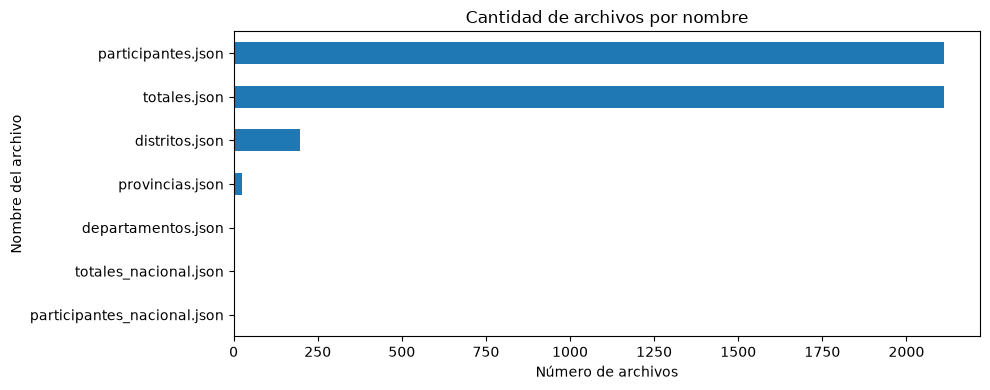

In [17]:
if not df_inventario.empty:
    conteo = df_inventario["archivo"].value_counts().head(20).sort_values()
    plt.figure(figsize=(10, max(4, len(conteo) * 0.35)))
    conteo.plot(kind="barh")
    plt.title("Cantidad de archivos por nombre")
    plt.xlabel("Número de archivos")
    plt.ylabel("Nombre del archivo")
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos para graficar.")


### 8.1. Distribución del tamaño de los JSON

Este histograma muestra si la mayoría de archivos son pequeños o si existen archivos mucho más grandes.


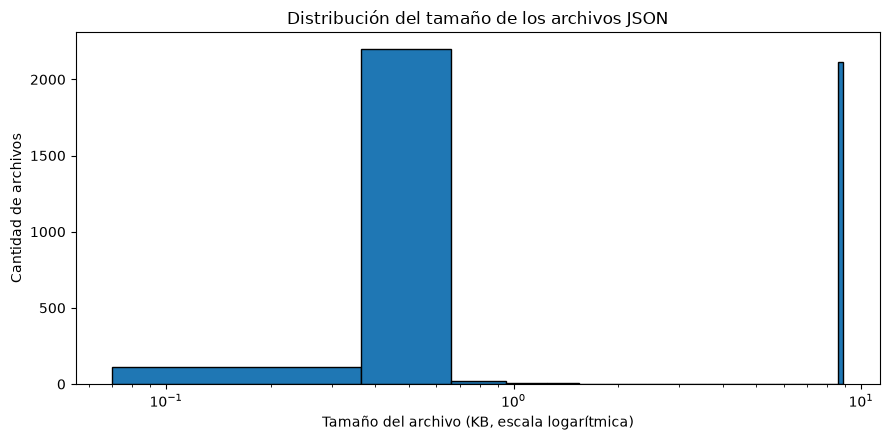

In [18]:
if not df_inventario.empty:
    tamanos = df_inventario.loc[df_inventario["tamano_kb"] > 0, "tamano_kb"]
    if not tamanos.empty:
        plt.figure(figsize=(9, 4.5))
        plt.hist(tamanos, bins=30, edgecolor="black")
        plt.xscale("log")
        plt.title("Distribución del tamaño de los archivos JSON")
        plt.xlabel("Tamaño del archivo (KB, escala logarítmica)")
        plt.ylabel("Cantidad de archivos")
        plt.tight_layout()
        plt.show()
    else:
        print("No hay archivos con tamaño mayor que cero.")
else:
    print("No hay inventario para graficar.")


### 8.2. Tamaño mediano por tipo de archivo

Compara el tamaño típico de `participantes.json`, `totales.json` y los catálogos.

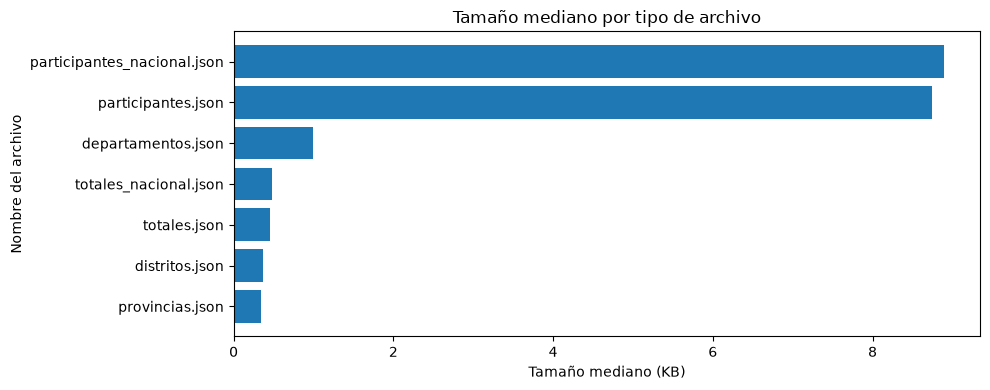

,archivo,mediana_kb,cantidad
3,participantes_nacional.json,8.90,1
2,participantes.json,8.75,2113
0,departamentos.json,1.00,1
6,totales_nacional.json,0.48,1
5,totales.json,0.46,2113
1,distritos.json,0.37,196
4,provincias.json,0.34,25


In [19]:
if not df_inventario.empty:
    resumen_tamanos = (df_inventario.groupby("archivo", as_index=False)
                       .agg(mediana_kb=("tamano_kb", "median"), cantidad=("archivo", "size"))
                       .sort_values("mediana_kb"))
    plt.figure(figsize=(10, max(4, len(resumen_tamanos) * 0.35)))
    plt.barh(resumen_tamanos["archivo"], resumen_tamanos["mediana_kb"])
    plt.title("Tamaño mediano por tipo de archivo")
    plt.xlabel("Tamaño mediano (KB)")
    plt.ylabel("Nombre del archivo")
    plt.tight_layout()
    plt.show()
    display(resumen_tamanos.sort_values("mediana_kb", ascending=False))
else:
    print("No hay inventario para graficar.")


### 8.3. Estado de lectura de los JSON

El gráfico distingue archivos válidos, vacíos y con error de lectura.


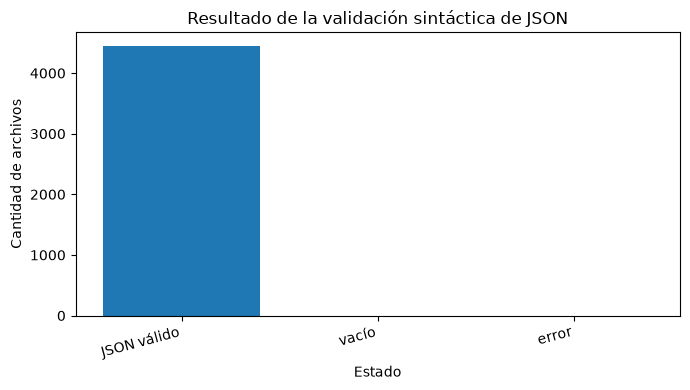

In [20]:
if not df_estado.empty:
    conteo_estado = df_estado["estado"].value_counts().reindex(["JSON válido", "vacío", "error"], fill_value=0)
    plt.figure(figsize=(7, 4))
    plt.bar(conteo_estado.index, conteo_estado.values)
    plt.title("Resultado de la validación sintáctica de JSON")
    plt.xlabel("Estado")
    plt.ylabel("Cantidad de archivos")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No hay resultados de validación.")


### 8.4. Estructura principal de los JSON

Muestra cuántos archivos tienen como elemento raíz un objeto (`dict`), una lista (`list`) u otro tipo. Esto ayuda a identificar si la API devuelve estructuras homogéneas o distintas.


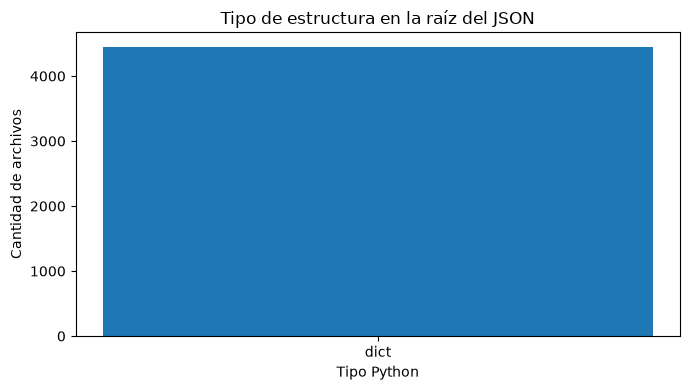

In [21]:
if not df_estado.empty and "tipo_raiz" in df_estado.columns:
    tipos_raiz = df_estado["tipo_raiz"].fillna("No disponible").value_counts()
    plt.figure(figsize=(7, 4))
    plt.bar(tipos_raiz.index.astype(str), tipos_raiz.values)
    plt.title("Tipo de estructura en la raíz del JSON")
    plt.xlabel("Tipo Python")
    plt.ylabel("Cantidad de archivos")
    plt.tight_layout()
    plt.show()
else:
    print("No hay tipos de raíz para graficar.")


### 8.5. Profundidad de las rutas de archivo

La profundidad es un indicador aproximado de cómo están organizados los archivos en carpetas.


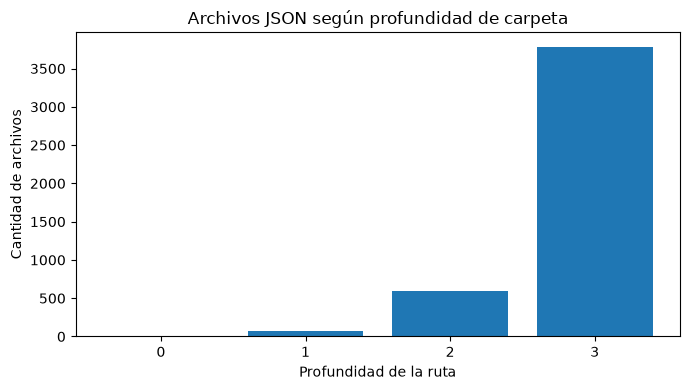

In [22]:
if not df_inventario.empty:
    if "profundidad" not in df_inventario.columns:
        df_inventario["profundidad"] = df_inventario["ruta_relativa"].apply(lambda x: len(Path(x).parts) - 1)
    niveles = df_inventario["profundidad"].value_counts().sort_index()
    plt.figure(figsize=(7, 4))
    plt.bar(niveles.index.astype(str), niveles.values)
    plt.title("Archivos JSON según profundidad de carpeta")
    plt.xlabel("Profundidad de la ruta")
    plt.ylabel("Cantidad de archivos")
    plt.tight_layout()
    plt.show()
else:
    print("No hay rutas para graficar.")


### 8.6. Campos con mayor cantidad de valores ausentes



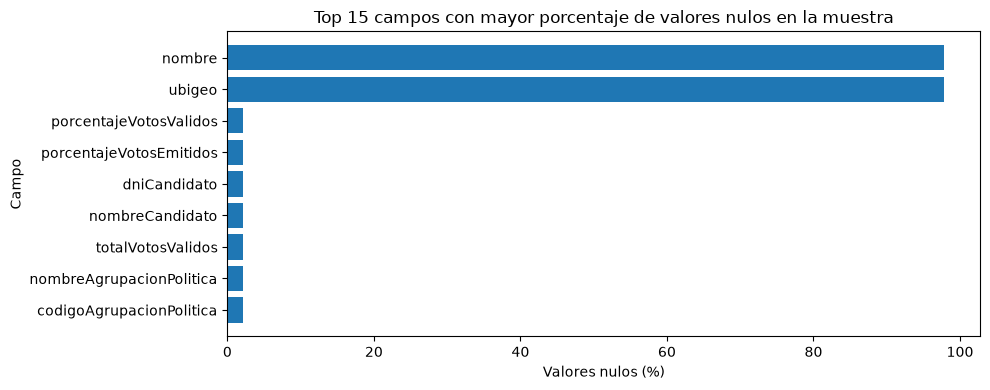

In [23]:
if not df_muestra.empty:
    resumen_nulos_graf = pd.DataFrame({
        "campo": df_muestra.columns,
        "porcentaje_nulos": [df_muestra[c].isna().mean() * 100 for c in df_muestra.columns]
    })
    resumen_nulos_graf = resumen_nulos_graf[resumen_nulos_graf["campo"] != "_archivo_origen"]
    resumen_nulos_graf = resumen_nulos_graf.sort_values("porcentaje_nulos", ascending=False).head(15)
    resumen_nulos_graf = resumen_nulos_graf.sort_values("porcentaje_nulos")
    plt.figure(figsize=(10, max(4, len(resumen_nulos_graf) * 0.35)))
    plt.barh(resumen_nulos_graf["campo"], resumen_nulos_graf["porcentaje_nulos"])
    plt.title("Top 15 campos con mayor porcentaje de valores nulos en la muestra")
    plt.xlabel("Valores nulos (%)")
    plt.ylabel("Campo")
    plt.tight_layout()
    plt.show()
else:
    print("La muestra no contiene registros tabulares para revisar valores ausentes.")


## 9. Resumen del EDA


In [24]:
total = len(archivos_json)
validos_n = int((df_estado["estado"] == "JSON válido").sum()) if not df_estado.empty else 0
vacios_n = int((df_estado["estado"] == "vacío").sum()) if not df_estado.empty else 0
errores_n = int((df_estado["estado"] == "error").sum()) if not df_estado.empty else 0
print("RESUMEN DEL EDA")
print("-" * 50)
print("Carpeta:", RUTA_JSON)
print(f"JSON encontrados: {total:,}")
print(f"JSON válidos: {validos_n:,}")
print(f"Archivos vacíos: {vacios_n:,}")
print(f"Errores de lectura: {errores_n:,}")
print(f"Registros tabulares de la muestra: {len(df_muestra):,}")
if total == 0: print("No se encontraron archivos: revisa la ruta o espera a que termine la descarga.")
elif vacios_n or errores_n: print("Hay archivos que necesitan revisión.")
else: print("Todos los archivos encontrados se pudieron parsear como JSON. Esto valida sintaxis, no exactitud ni cobertura electoral.")


RESUMEN DEL EDA
--------------------------------------------------
Carpeta: C:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis\data\raw\ONPE_2026\Peru
JSON encontrados: 4,450
JSON válidos: 4,450
Archivos vacíos: 0
Errores de lectura: 0
Registros tabulares de la muestra: 1,803
Todos los archivos encontrados se pudieron parsear como JSON. Esto valida sintaxis, no exactitud ni cobertura electoral.
